# Sistem Rekomendasi: Collaborative Filtering (User-Based)

**Collaborative Filtering** merekomendasikan item kepada seorang pengguna berdasarkan pola penilaian (_rating_) dari pengguna lain yang memiliki selera serupa.

---

### 1. Kemiripan Antar Pengguna (Cosine Similarity)

Mengukur kemiripan selera antara pengguna $u$ dan pengguna $v$ berdasarkan vektor _rating_ mereka (rentang `0.0` hingga `1.0`):
$$\text{sim}(u, v) = \frac{R_u \cdot R_v}{\|R_u\| \|R_v\|} = \frac{\sum_{i \in I} R_{u,i} R_{v,i}}{\sqrt{\sum_{i \in I} R_{u,i}^2} \sqrt{\sum_{i \in I} R_{v,i}^2}}$$

- **Fungsi Tiap Simbol:**
  - $u, v$: Dua pengguna yang sedang dibandingkan kemiripan seleranya.
  - $R_u, R_v$: Vektor skor _rating_ yang diberikan oleh pengguna $u$ dan $v$.
  - $I$: Himpunan seluruh item yang tersedia.
  - $R_{u,i}, R_{v,i}$: Nilai _rating_ dari pengguna $u$ dan $v$ pada item ke-$i$ (bernilai `0` jika belum dinilai).
  - $\|R_u\|, \|R_v\|$: Panjang geometris (_Euclidean norm_) dari masing-masing vektor _rating_.
- **Contoh Sederhana:**
  Pengguna A memberi _rating_ `[5, 3]` dan Pengguna B memberi _rating_ `[4, 3]` pada 2 film:
  1. **Perkalian Titik ($R_A \cdot R_B$)**: $(5 \times 4) + (3 \times 3) = 20 + 9 = 29$
  2. **Panjang Vektor**: $\|R_A\| = \sqrt{5^2 + 3^2} = \sqrt{34} \approx 5.831$, dan $\|R_B\| = \sqrt{4^2 + 3^2} = \sqrt{25} = 5.0$
  3. **Hasil**: $\frac{29}{5.831 \times 5.0} \approx \mathbf{0.9947}$ (Kemiripan selera **99.47%**)

---

### 2. Prediksi Skor Rating (Weighted Average)

Memprediksi _rating_ pengguna $u$ untuk item $i$ yang belum ditonton berdasarkan rata-rata tertimbang dari pengguna lain ($v$):
$$\hat{r}_{u,i} = \frac{\sum_{v \in N} \text{sim}(u, v) \cdot R_{v,i}}{\sum_{v \in N} |\text{sim}(u, v)|}$$

- **Fungsi Tiap Simbol:**
  - $\hat{r}_{u,i}$: Skor prediksi _rating_ pengguna $u$ terhadap item $i$.
  - $N$: Kelompok pengguna lain yang sudah menilai item $i$.
  - $\text{sim}(u, v)$: Bobot kemiripan antara pengguna target $u$ dengan tetangga $v$.
  - $R_{v,i}$: _Rating_ aktual yang diberikan pengguna $v$ pada item $i$.
  - $|\text{sim}(u, v)|$: Nilai mutlak dari skor kemiripan sebagai pembagi normalisasi.
- **Contoh Sederhana:**
  Pengguna B (kemiripan `0.9`) memberi _rating_ `5` dan Pengguna C (kemiripan `0.4`) memberi _rating_ `2` pada film X:
  $$\hat{r}_{A,X} = \frac{(0.9 \times 5) + (0.4 \times 2)}{0.9 + 0.4} = \frac{4.5 + 0.8}{1.3} = \frac{5.3}{1.3} \approx \mathbf{4.08}$$

---

### 3. Kelebihan & Kekurangan

#### Kelebihan (Pros)

- **Tidak Membutuhkan Analisis Konten:** Bekerja murni berdasarkan riwayat interaksi atau _rating_, tanpa perlu ekstraksi metadata (genre, sinopsis, atau kategori).
- **Mampu Menemukan Minat Baru (_Serendipity_):** Dapat merekomendasikan item di luar kategori kebiasaan pengguna jika pengguna lain yang berselera mirip menyukainya.
- **Akurasi Meningkat Seiring Waktu:** Semakin banyak data interaksi yang terkumpul, semakin akurat sistem mengenali pola preferensi pengguna.

#### Kekurangan (Cons)

- **Masalah _Cold-Start_:** Sulit memberikan rekomendasi akurat untuk pengguna baru yang belum memberi _rating_, maupun item baru yang belum pernah dinilai siapa pun.
- **Keterbatasan Data Jarang (_Data Sparsity_):** Jika jumlah item sangat banyak sementara tiap pengguna hanya menilai sedikit item, matriks _rating_ menjadi kosong dan kemiripan sulit dihitung.
- **Beban Komputasi (_Scalability_):** Menghitung kemiripan antar semua pasang pengguna menjadi lambat dan memakan banyak memori ketika jumlah pengguna mencapai jutaan.


In [1]:
from sklearn.metrics.pairwise import cosine_similarity

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
def computeUserSimilarity(ratingMatrix: pd.DataFrame) -> pd.DataFrame:
  '''
  Menghitung matriks kemiripan antar pengguna menggunakan Cosine Similarity.

  Args:
    ratingMatrix (pd.DataFrame): Matriks pivot dengan baris userId dan kolom itemId.

  Returns:
    pd.DataFrame: Matriks persegi berisi skor kemiripan antar pengguna.
  '''
  similarityArray = cosine_similarity(ratingMatrix)
  similarityFrame = pd.DataFrame(
    similarityArray,
    columns=ratingMatrix.index,
    index=ratingMatrix.index,
  )
  return similarityFrame

def createDataset() -> pd.DataFrame:
  '''
  Membuat dataset interaksi contoh berisi penilaian pengguna terhadap film.

  Returns:
    pd.DataFrame: Tabel berisi kolom itemId, rating, dan userId.
  '''
  interactionData = {
    'itemId': [
      'The Raid',
      'Headshot',
      'Laskar Pelangi',
      'The Raid',
      'Headshot',
      'Gundala',
      'Laskar Pelangi',
      'Cek Toko Sebelah',
      'Warkop DKI Reborn',
      'The Raid',
      'Gundala',
      'Cek Toko Sebelah',
    ],
    'rating': [
      5.0,
      4.5,
      1.0,
      4.5,
      5.0,
      4.0,
      5.0,
      4.5,
      4.0,
      1.5,
      2.0,
      5.0,
    ],
    'userId': [
      'User_A',
      'User_A',
      'User_A',
      'User_B',
      'User_B',
      'User_B',
      'User_C',
      'User_C',
      'User_C',
      'User_D',
      'User_D',
      'User_D',
    ],
  }
  return pd.DataFrame(interactionData)

def getRecommendations(
  ratingMatrix: pd.DataFrame,
  similarityFrame: pd.DataFrame,
  targetUser: str,
  topN: int,
) -> pd.DataFrame:
  '''
  Memprediksi skor rating dan mengambil rekomendasi item terbaik bagi pengguna target.

  Args:
    ratingMatrix (pd.DataFrame): Matriks rating pengguna terhadap item.
    similarityFrame (pd.DataFrame): Matriks skor kemiripan antar pengguna.
    targetUser (str): ID pengguna yang akan diberikan rekomendasi.
    topN (int): Jumlah rekomendasi teratas yang dikembalikan.

  Returns:
    pd.DataFrame: Daftar item rekomendasi beserta prediksi skor ratingnya.
  '''
  itemRatings = pd.Series(dtype=float)
  otherUsers = similarityFrame.index.drop(targetUser)
  predictions = []
  raterMask = pd.Series(dtype=bool)
  resultFrame = pd.DataFrame()
  simWeights = similarityFrame.loc[otherUsers, targetUser]
  unwatchedItems = ratingMatrix.columns[ratingMatrix.loc[targetUser] == 0]
  weightedSum = 0.0
  weightTotal = 0.0

  # Menghitung prediksi rating untuk setiap item yang belum ditonton targetUser
  for item in unwatchedItems:
    itemRatings = ratingMatrix.loc[otherUsers, item]
    raterMask = itemRatings > 0

    if raterMask.any():
      weightedSum = np.dot(simWeights[raterMask], itemRatings[raterMask])
      weightTotal = np.abs(simWeights[raterMask]).sum()
      predictions.append({
        'itemId': item,
        'predictedRating': round(float(weightedSum / weightTotal), 4),
      })

  # Mengurutkan hasil prediksi dari skor tertinggi ke terendah
  resultFrame = pd.DataFrame(predictions).sort_values(
    ascending=False,
    by='predictedRating',
  ).head(topN).reset_index(drop=True)
  return resultFrame

def plotResults(
  recommendationFrame: pd.DataFrame,
  similarityFrame: pd.DataFrame,
  targetUser: str,
) -> None:
  '''
  Menampilkan visualisasi heatmap kemiripan pengguna dan diagram batang prediksi rating.

  Args:
    recommendationFrame (pd.DataFrame): Tabel hasil rekomendasi item teratas.
    similarityFrame (pd.DataFrame): Matriks skor kemiripan antar pengguna.
    targetUser (str): ID pengguna target rekomendasi.
  '''
  axes = None
  figure = None

  sns.set_theme(style='whitegrid')
  figure, axes = plt.subplots(1, 2, figsize=(14, 5))

  # Plot 1: Heatmap kemiripan antar pengguna pada subplot kiri (axes[0])
  sns.heatmap(
    annot=True,
    ax=axes[0],
    cmap='YlGnBu',
    data=similarityFrame,
    fmt='.2f',
  )
  axes[0].set_title('User-to-User Cosine Similarity Matrix', pad=12)

  # Plot 2: Diagram batang prediksi rating item pada subplot kanan (axes[1])
  sns.barplot(
    ax=axes[1],
    data=recommendationFrame,
    hue='itemId',
    legend=False,
    palette='viridis',
    x='predictedRating',
    y='itemId',
  )
  axes[1].set_xlim(0, 5.5)
  axes[1].set_xlabel('Predicted Rating (1.0 - 5.0)')
  axes[1].set_ylabel('Item ID')
  axes[1].set_title(f"Top Recommendations for '{targetUser}'", pad=12)

  # Menambahkan label skor prediksi tepat di ujung setiap batang
  for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f', padding=4)

  plt.tight_layout()
  plt.show()

itemId,Cek Toko Sebelah,Gundala,Headshot,Laskar Pelangi,The Raid,Warkop DKI Reborn
userId,,,,,,
User_A,0.0,0.0,4.5,1.0,5.0,0.0
User_B,0.0,4.0,5.0,0.0,4.5,0.0
User_C,4.5,0.0,0.0,5.0,0.0,4.0
User_D,5.0,2.0,0.0,0.0,1.5,0.0


,itemId,predictedRating
0,Cek Toko Sebelah,4.8387
1,Warkop DKI Reborn,4.0000
2,Gundala,3.6216


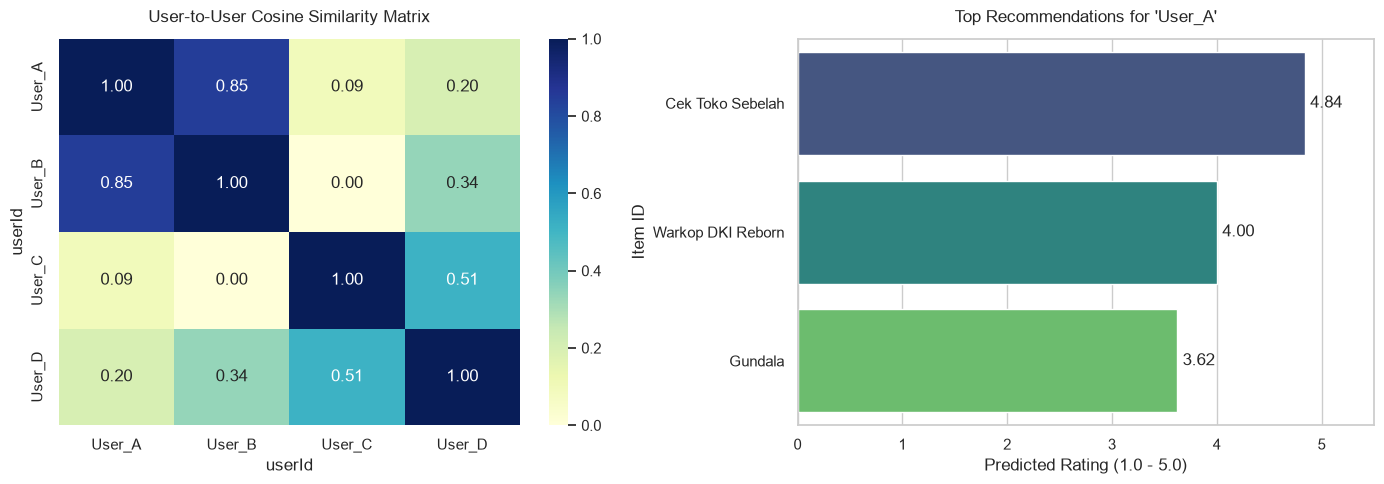

In [3]:
interactionFrame = createDataset()
ratingMatrix = interactionFrame.pivot_table(
  columns='itemId',
  fill_value=0.0,
  index='userId',
  values='rating',
)
recommendationFrame = pd.DataFrame()
similarityFrame = computeUserSimilarity(ratingMatrix=ratingMatrix)
targetUser = 'User_A'

# Mengambil 3 rekomendasi film teratas untuk User_A
recommendationFrame = getRecommendations(
  ratingMatrix=ratingMatrix,
  similarityFrame=similarityFrame,
  targetUser=targetUser,
  topN=3,
)

# Menampilkan matriks rating, tabel rekomendasi, dan grafik visualisasi
display(ratingMatrix)
display(recommendationFrame)
plotResults(
  recommendationFrame=recommendationFrame,
  similarityFrame=similarityFrame,
  targetUser=targetUser,
)